# Chronos-2

**Chronos-2** is Amazon's pretrained **time series foundation model** (120M parameters). Like TimesFM-3 and Timestral, it is **zero-shot**: it is not trained on our data. We pass the history as *context* and it directly outputs a probabilistic forecast for the requested horizon.

- Works with univariate series, multiple series and covariates (past and future).
- Probabilistic: returns the quantiles we ask for (e.g. 0.1, 0.5, 0.9).
- Smaller variants are available (e.g. `chronos-2-small`, 28M) for faster CPU inference.

**Pros:** no training or tuning, built-in uncertainty, covariate support, Apache 2.0 license (commercial use allowed).
**Cons:** black box, slower than classical models, zero-shot may miss domain-specific patterns.

As with the other models, Chronos-2 predicts only $\hat{Z}_2(t)$ (the log error), and the forecast is rebuilt with $\hat{X}(t) = e^{\hat{Z}_2(t) + (\alpha_0 + \alpha_1 t)}$.

### Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter('ignore', ConvergenceWarning)

In [3]:
import time
import math
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from matplotlib import image as mpimg

In [4]:
def transform_date(date):
    try:
        new_date = date.year + (date.month - 1)/12 + date.day/365
        return new_date
    except:
        return float('nan')

In [5]:
def transform_value(value):
    try:
        return float(value)
    except:
        return float('nan')

In [6]:
start = time.time()

# 1. Read DataFrame

In [7]:
df = pd.read_csv('AirPassengers.csv')
df = df.rename(columns = {'Month': 'Time', 'Passengers': 'X_t'})
df['Time'] = pd.to_datetime(df['Time'])
df['Time'] = df['Time'].map(lambda x: transform_date(x))
df['X_t'] = df['X_t'].map(lambda x: transform_value(x))
df = df.dropna()

# 2. Split

In [8]:
train = df[df['Time'] <= 1955]
val = df[(df['Time'] > 1955) & (df['Time'] <= 1958)]
test = df[df['Time'] > 1958]

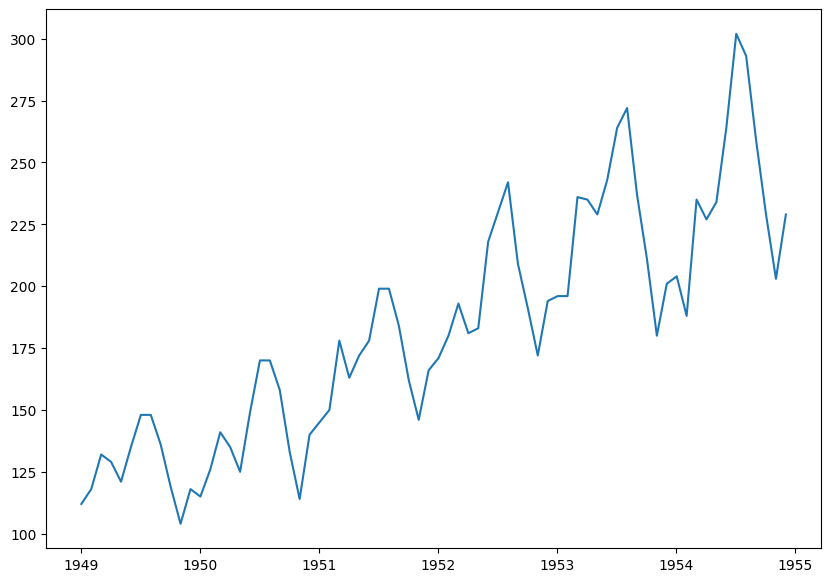

In [9]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['X_t'])
plt.show()

# 3. Box Cox

In [10]:
train['log_X_t'] = np.log(train['X_t'])
val['log_X_t'] = np.log(val['X_t'])
test['log_X_t'] = np.log(test['X_t'])

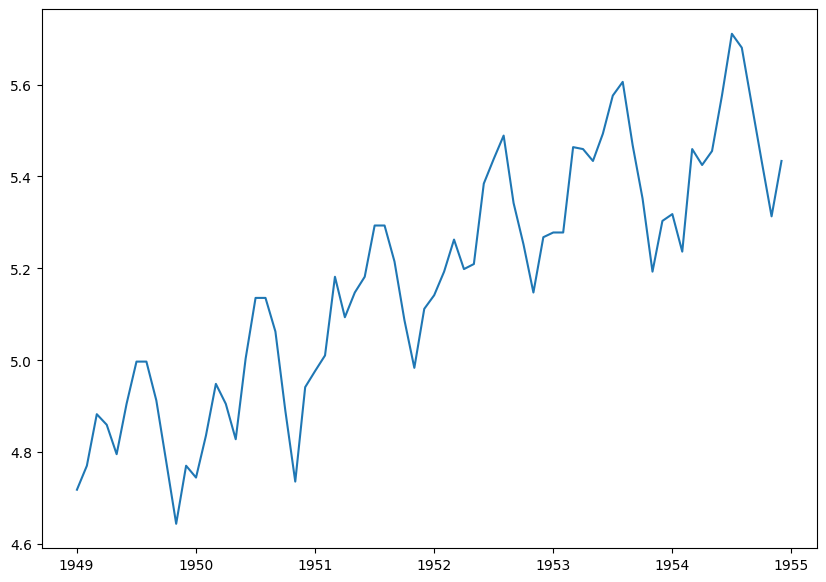

In [11]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['log_X_t'])
plt.show()

# 4. Exogen Regression

We dont have exogen variables.

# 5. Endogen Regression

We going to use linear trend.

In [12]:
from sklearn.linear_model import LinearRegression

In [13]:
reg = LinearRegression().fit(train[['Time']], train['log_X_t'])

In [14]:
train['log_trend'] = reg.predict(train[['Time']])
val['log_trend'] = reg.predict(val[['Time']])
test['log_trend'] = reg.predict(test[['Time']])

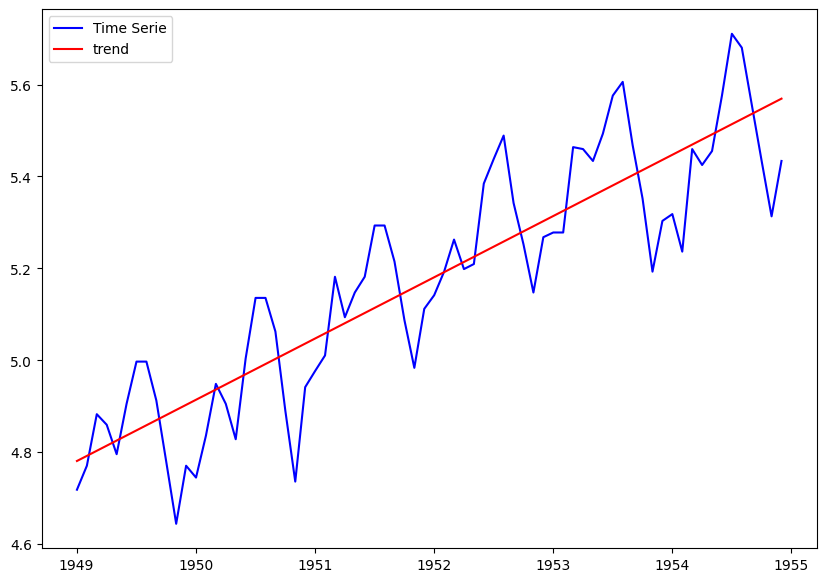

In [15]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['log_X_t'], color = 'blue', label = 'Time Serie')
plt.plot(train['Time'], train['log_trend'], color = 'red', label = 'trend')
plt.legend()
plt.show()

In [16]:
train['log_error'] = train['log_X_t'] - train['log_trend']
val['log_error'] = val['log_X_t'] - val['log_trend']
test['log_error'] = test['log_X_t'] - test['log_trend']

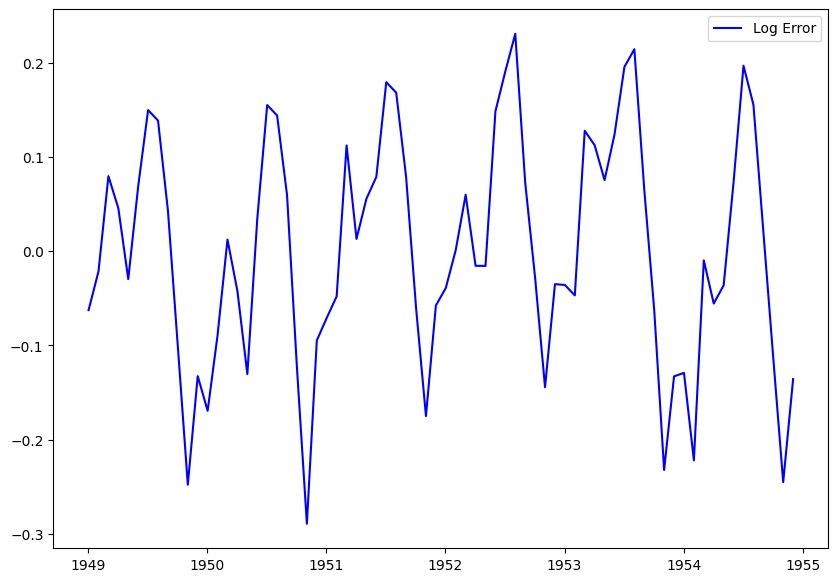

In [17]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['log_error'], color = 'blue', label = 'Log Error')
plt.legend()
plt.show()

# Evaluation framework

Every model predicts only $\hat{Z}_2(t)$ (the log error). The forecast in the original scale is:

$$\hat{X}(t) = e^{\hat{Z}_2(t) + (\alpha_0 + \alpha_1 t)}$$

We compare models on the validation set with RMSE and MAPE, always in the original scale (passengers).

# 6. Chronos-2

In [18]:
from chronos import Chronos2Pipeline

pipeline_chr = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu")

def to_ds(d):
    year = np.floor(d['Time']).astype(int)
    month = ((d['Time'] % 1) * 12).round().astype(int) + 1
    return pd.to_datetime(pd.DataFrame({'year': year, 'month': month, 'day': 1}))

W1103 14:57:34.719000 30274 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 170/170 [00:00<00:00, 24544.98it/s]


In [19]:
QUANTILES = [0.1, 0.5, 0.9]
horizon = len(val) + len(test)   # 72 months

context_df = pd.DataFrame({
    'id': 'Z2',
    'timestamp': to_ds(train).values,
    'target': train['log_error'].values,
})

pred_df = pipeline_chr.predict_df(
    context_df,
    prediction_length=horizon,
    quantile_levels=QUANTILES,
    id_column='id',
    timestamp_column='timestamp',
    target='target',
)

z2_hat_future = pred_df['0.5'].values   # median, shape (72,)
z2_q10 = pred_df['0.1'].values
z2_q90 = pred_df['0.9'].values

z2_hat_val = z2_hat_future[:len(val)]
z2_hat_test = z2_hat_future[len(val):]

In [20]:
MIN_CONTEXT = 24
ts_train = to_ds(train).values
z2_train = train['log_error'].values

context_steps_df = pd.concat([
    pd.DataFrame({'id': t, 'timestamp': ts_train[:t], 'target': z2_train[:t]})
    for t in range(MIN_CONTEXT, len(train))
], ignore_index=True)

pred_steps_df = pipeline_chr.predict_df(
    context_steps_df,
    prediction_length=1,
    quantile_levels=QUANTILES,
    id_column='id',
    timestamp_column='timestamp',
    target='target',
)

z2_hat_train = np.full(len(train), np.nan)
pred_steps_df = pred_steps_df.sort_values('id')
z2_hat_train[pred_steps_df['id'].astype(int).values] = pred_steps_df['0.5'].values

In [21]:
train['X_hat_chr'] = np.exp(z2_hat_train + train['log_trend'].values)
val['X_hat_chr'] = np.exp(z2_hat_val + val['log_trend'].values)
test['X_hat_chr'] = np.exp(z2_hat_test + test['log_trend'].values)

# 7. Evaluate

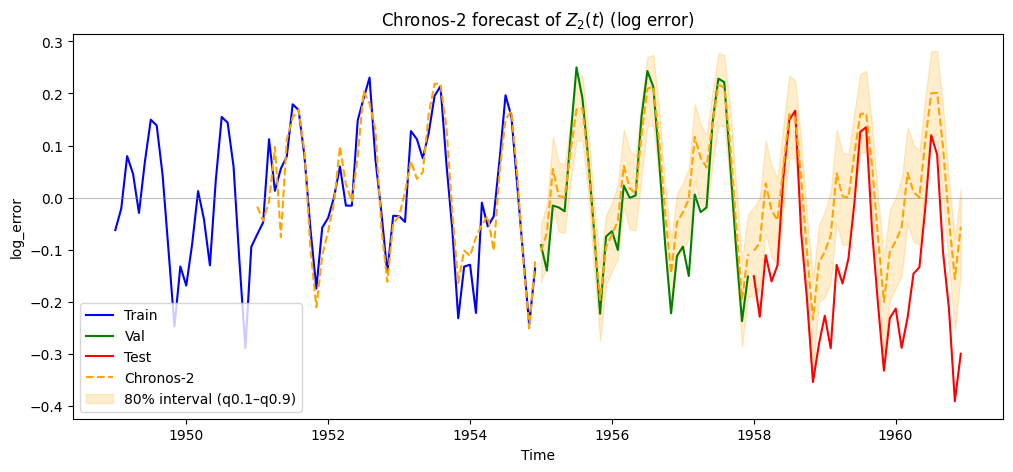

In [22]:
times_future = np.concatenate([val['Time'].values, test['Time'].values])

plt.figure(figsize=(12, 5))
plt.plot(train['Time'], train['log_error'], color='blue', label='Train')
plt.plot(val['Time'], val['log_error'], color='green', label='Val')
plt.plot(test['Time'], test['log_error'], color='red', label='Test')
plt.plot(train['Time'], z2_hat_train, '--', color='orange', label='Chronos-2')
plt.plot(val['Time'], z2_hat_val, '--', color='orange')
plt.plot(test['Time'], z2_hat_test, '--', color='orange')
plt.fill_between(times_future, z2_q10, z2_q90,
                 color='orange', alpha=0.2, label='80% interval (q0.1–q0.9)')
plt.axhline(0, color='gray', linewidth=0.8, alpha=0.5)
plt.title(r'Chronos-2 forecast of $Z_2(t)$ (log error)')
plt.xlabel('Time'); plt.ylabel('log_error')
plt.legend(); plt.show()

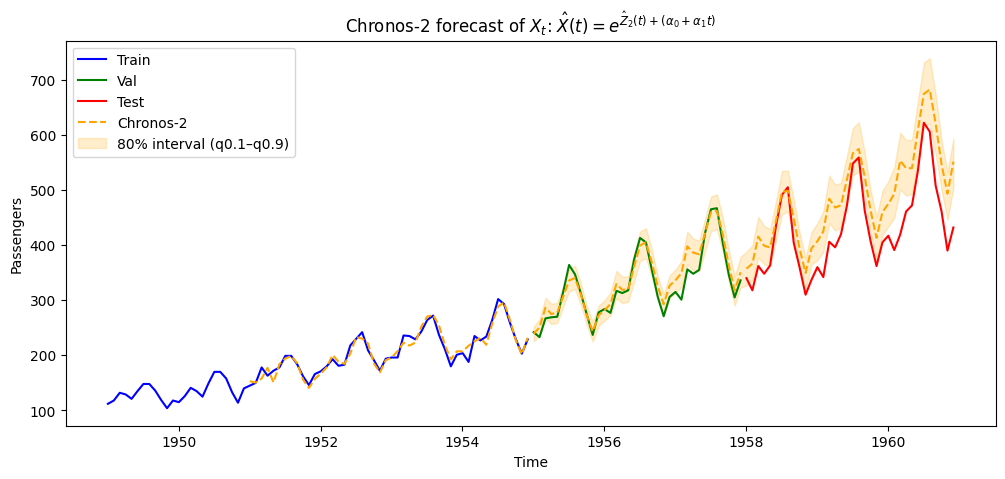

In [23]:
trend_future = np.concatenate([val['log_trend'].values, test['log_trend'].values])

plt.figure(figsize=(12, 5))
plt.plot(train['Time'], train['X_t'], color='blue', label='Train')
plt.plot(val['Time'], val['X_t'], color='green', label='Val')
plt.plot(test['Time'], test['X_t'], color='red', label='Test')
plt.plot(train['Time'], train['X_hat_chr'], '--', color='orange', label='Chronos-2')
plt.plot(val['Time'], val['X_hat_chr'], '--', color='orange')
plt.plot(test['Time'], test['X_hat_chr'], '--', color='orange')
plt.fill_between(times_future,
                 np.exp(z2_q10 + trend_future),
                 np.exp(z2_q90 + trend_future),
                 color='orange', alpha=0.2, label='80% interval (q0.1–q0.9)')
plt.title(r'Chronos-2 forecast of $X_t$: $\hat{X}(t) = e^{\hat{Z}_2(t) + (\alpha_0 + \alpha_1 t)}$')
plt.xlabel('Time'); plt.ylabel('Passengers')
plt.legend(); plt.show()

In [24]:
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)

def performance(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mask = ~np.isnan(y_pred)   # skip months without prediction (first MIN_CONTEXT of train)
    y_true, y_pred = y_true[mask], y_pred[mask]
    return {
        'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE (%)': mean_absolute_percentage_error(y_true, y_pred) * 100,
        'R2': r2_score(y_true, y_pred),
    }

rows = [
    {'Scale': 'log_error', 'Set': 'train', **performance(train['log_error'], z2_hat_train)},
    {'Scale': 'log_error', 'Set': 'val',   **performance(val['log_error'], z2_hat_val)},
    {'Scale': 'log_error', 'Set': 'test',  **performance(test['log_error'], z2_hat_test)},
    {'Scale': 'X_t',       'Set': 'train', **performance(train['X_t'], train['X_hat_chr'])},
    {'Scale': 'X_t',       'Set': 'val',   **performance(val['X_t'], val['X_hat_chr'])},
    {'Scale': 'X_t',       'Set': 'test',  **performance(test['X_t'], test['X_hat_chr'])},
]

metrics_chr_df = pd.DataFrame(rows).set_index(['Scale', 'Set']).round(4)
metrics_chr_df

RMSE      MAE  MAPE (%)      R2
Scale     Set                                      
log_error train   0.0507   0.0389   92.1346  0.8284
          val     0.0541   0.0421  194.1974  0.8437
          test    0.1443   0.1290  115.1273  0.0670
X_t       train  10.0257   7.8603    3.8848  0.9263
          val    18.0263  13.8204    4.3293  0.9060
          test   66.0974  58.3227   14.0115  0.2859